# Commuting in UK cities: comparison

Reads the summary tables written by the per-city notebooks (`commuting_<city>.ipynb`, all with the same rule, months and thresholds)
and puts them side by side: panel sizes, how many residents get a work cell and why not, where residents work, and commute distances.
Run the city notebooks first; a city without results is skipped.

In [1]:
import os
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

PERIOD = "2024-05_2024-06"   # results of the two-month run of the city notebooks
COUNTRY = "GBR"
CITIES  = {"DEU": ["munich", "berlin", "hamburg", "frankfurt", "cologne"], "FRA": ["paris", "lyon", "marseille", "nice"], "GBR": ["london", "manchester", "birmingham", "glasgow", "liverpool"]}[COUNTRY]
SCRATCH = Path(f"/scratch/project_2022768/{os.environ['USER']}/locomizer")
ACCENT = "#2A6DD9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e7eb",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})

res = {}
for key in CITIES:
    d = SCRATCH / "results" / COUNTRY / f"{key}_{PERIOD}"
    if not (d / "counts.csv").exists():
        print("no results yet for", key); continue
    res[key] = {f.stem: pd.read_csv(f) for f in d.glob("*.csv")}
    res[key]["counts"] = pd.read_csv(d / "counts.csv", index_col=0).iloc[:, 0]
names = {key: res[key]["meta"].city.iloc[0] for key in res}
print("cities with results:", list(names.values()))

cities with results: ['London', 'Manchester', 'Birmingham', 'Glasgow', 'Liverpool']


## 1. Panel size per city

In [2]:
rows = []
for key, r in res.items():
    c, m = r["counts"], r["meta"].iloc[0]
    rows.append({"city": names[key], "FUA km²": m.fua_km2, "city km²": m.city_km2,
                 "FUA residents": c["FUA residents"], "with work cell": c["FUA residents with a work cell"],
                 "share with work cell": f"{100*c['FUA residents with a work cell']/c['FUA residents']:.0f}%",
                 "commuters (home or work in FUA)": c["commuters with home or work in the FUA"],
                 "city residents": c["city residents"], "workers in the city": c["workers in the city (any home)"]})
panel = pd.DataFrame(rows).set_index("city"); panel

,FUA km²,city km²,FUA residents,with work cell,share with work cell,commuters (home or work in FUA),city residents,workers in the city
city,,,,,,,,
London,6978,1576,1264889,823470,65%,918075,722555,485389
Manchester,3123,116,327085,225998,69%,249391,33846,30541
Birmingham,2154,268,301408,203557,68%,225598,86750,61078
Glasgow,3373,175,131666,88921,68%,96016,33881,27785
Liverpool,993,112,132201,91110,69%,103641,31294,24674


## 2. Why residents have no work cell (share of FUA residents)

In [3]:
reasons = pd.concat([r["reasons"].assign(city=names[k]) for k, r in res.items()])
reasons["reason"] = reasons.reason.str[2:]
tab = reasons.pivot(index="reason", columns="city", values="pct_of_residents").fillna(0).round(1)
tab

city,Birmingham,Glasgow,Liverpool,London,Manchester
reason,,,,,
"away from home, but scattered over cells",20.7,20.9,20.3,22.3,19.6
daytime signals only at the home cell,11.6,11.4,10.6,12.5,11.1
has work cell in FUA,60.0,61.9,58.7,59.3,61.6
has work cell outside FUA,7.5,5.6,10.2,5.8,7.5
no 09-17 signals on enough working days,0.1,0.2,0.1,0.1,0.1
seen on too few working days,0.0,0.0,0.0,0.0,0.0


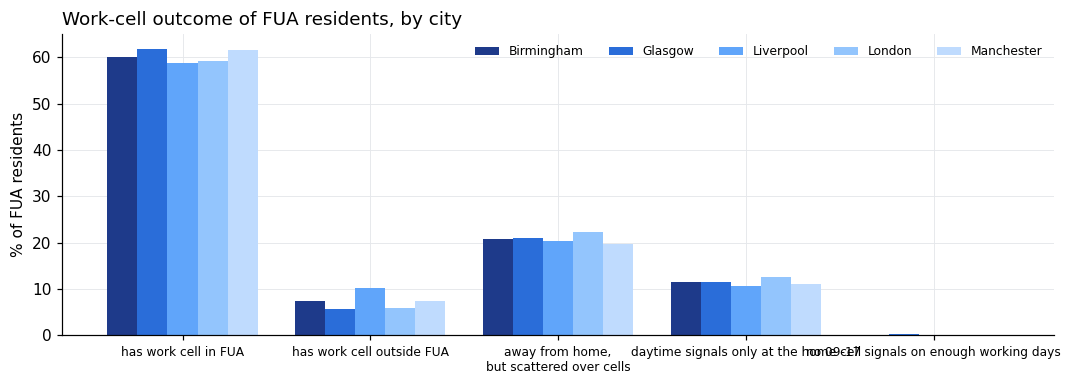

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
order = ["has work cell in FUA", "has work cell outside FUA", "away from home, but scattered over cells", "daytime signals only at the home cell", "no 09-17 signals on enough working days"]
order = [o for o in order if o in tab.index]
x = np.arange(len(order)); w = 0.8 / max(len(tab.columns), 1)
shades = ["#1e3a8a", "#2A6DD9", "#60a5fa", "#93c5fd", "#bfdbfe"]
for i, city in enumerate(tab.columns):
    ax.bar(x + i * w - 0.4 + w / 2, tab.loc[order, city], width=w, color=shades[i % len(shades)], label=city)
ax.set_xticks(x); ax.set_xticklabels([o.replace(", ", ",\n") for o in order], fontsize=8)
ax.set_ylabel("% of FUA residents"); ax.set_title("Work-cell outcome of FUA residents, by city", loc="left"); ax.legend(frameon=False, ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

## 3. Where do city residents work, and where do city workers live?

In [5]:
rows = []
for key, r in res.items():
    c = r["counts"]
    rows.append({"city": names[key],
                 "city residents with work cell": c["city residents with a work cell"],
                 "of which work inside the city": f"{100*c['  ... working inside the city']/c['city residents with a work cell']:.0f}%",
                 "workers in the city": c["workers in the city (any home)"],
                 "of which live inside the city": f"{100*c['  ... working inside the city']/c['workers in the city (any home)']:.0f}%"})
pd.DataFrame(rows).set_index("city")

,city residents with work cell,of which work inside the city,workers in the city,of which live inside the city
city,,,,
London,452352,86%,485389,80%
Manchester,21215,61%,30541,42%
Birmingham,55208,71%,61078,64%
Glasgow,21880,71%,27785,56%
Liverpool,20581,71%,24674,59%


## 4. Commute distance (km between home and work cell centres, home and work both in the metro)


In [6]:
dist = pd.concat([r["distance"].assign(city=names[k]) for k, r in res.items()])
pooled = dist[dist["group"] == "home and work in metro"].set_index("city")[["count", "25%", "50%", "75%"]]
missing = [c for c in names.values() if c not in pooled.index]
if missing: print("no pooled distance row yet, re-run the city notebook for:", missing)
pooled.reindex(names.values()).round(1)


,count,25%,50%,75%
city,,,,
London,750672.0,0.9,2.6,8.3
Manchester,201541.0,0.9,2.3,6.1
Birmingham,180961.0,0.9,2.6,6.5
Glasgow,81499.0,0.9,2.3,6.8
Liverpool,77668.0,0.9,2.3,5.6


## 5. Strongest district-to-district flows per city

In [7]:
pd.concat([r["district_flows"].head(5).assign(city=names[k]) for k, r in res.items()]).set_index(["city", "home_district", "work_district"])

users
city       home_district                                      work_district                                        
London     West Essex                                         Hertfordshire                                    4124
           Essex Thames Gateway                               Southend-on-Sea                                  3532
           East Surrey                                        Merton, Kingston upon Thames and Sutton          3199
           Hertfordshire                                      West Essex                                       2989
           Southend-on-Sea                                    Essex Thames Gateway                             2941
Manchester Greater Manchester South East                      Manchester                                       4326
           Greater Manchester South West                      Manchester                                       4181
           Greater Manchester North East                      Manchester                                       3452
           Manchester                                         Greater Manchester South West                    2584
           Greater Manchester North West                      Greater Manchester South West                    2423
Birmingham Birmingham                                         Solihull                                         4183
           Solihull                                           Birmingham                                       3795
           Sandwell                                           Birmingham                                       3499
           Dudley                                             Sandwell                                         2987
           Staffordshire CC                                   Birmingham                                       2499
Glasgow    Inverclyde, East Renfrewshire and Renfrewshire     Glasgow City                                     3301
           South Lanarkshire                                  Glasgow City                                     2257
           East Dunbartonshire, West Dunbartonshire and He... Glasgow City                                     2224
           North Lanarkshire                                  Glasgow City                                     1970
           Glasgow City                                       Inverclyde, East Renfrewshire and Renfrewshire   1654
Liverpool  East Merseyside                                    Liverpool                                        3611
           Sefton                                             Liverpool                                        2140
           Liverpool                                          East Merseyside                                  2086
           Wirral                                             Liverpool                                        1352
           Liverpool                                          Sefton                                           1332